In [1]:
import numpy as np

data = np.load("datasets/fashion_mnist.npz")
x_train, y_train = data["x_train"], data["y_train"]
x_test, y_test = data["x_test"], data["y_test"]

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

# нормализация в [0, 1] и добавление канала (28,28) -> (28,28,1)
x_train = x_train.astype("float32")[..., None] / 255.0
x_test = x_test.astype("float32")[..., None] / 255.0

print("train:", x_train.shape, y_train.shape)
print("test:", x_test.shape, y_test.shape)

train: (60000, 28, 28, 1) (60000,)
test: (10000, 28, 28, 1) (10000,)


In [2]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=128,
)

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"test accuracy: {test_acc:.4f}")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7776 - loss: 0.6252 - val_accuracy: 0.8415 - val_loss: 0.4252
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8421 - loss: 0.4412 - val_accuracy: 0.8588 - val_loss: 0.3906
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8545 - loss: 0.4010 - val_accuracy: 0.8603 - val_loss: 0.3734
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8648 - loss: 0.3730 - val_accuracy: 0.8758 - val_loss: 0.3489
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8710 - loss: 0.3541 - val_accuracy: 0.8742 - val_loss: 0.3332
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8736 - loss: 0.3424 - val_accuracy: 0.8803 - val_loss: 0.3282
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8776 - loss: 0.3329 - val_accuracy: 0.8822 - val_loss: 0.3224
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8803 - loss: 0.3226 - val_accuracy: 0.

In [4]:
import os

os.makedirs("model", exist_ok=True)
model.save("model/fashion_mnist_cnn.keras")
print("saved to model/fashion_mnist_cnn.keras")

saved to model/fashion_mnist_cnn.keras


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


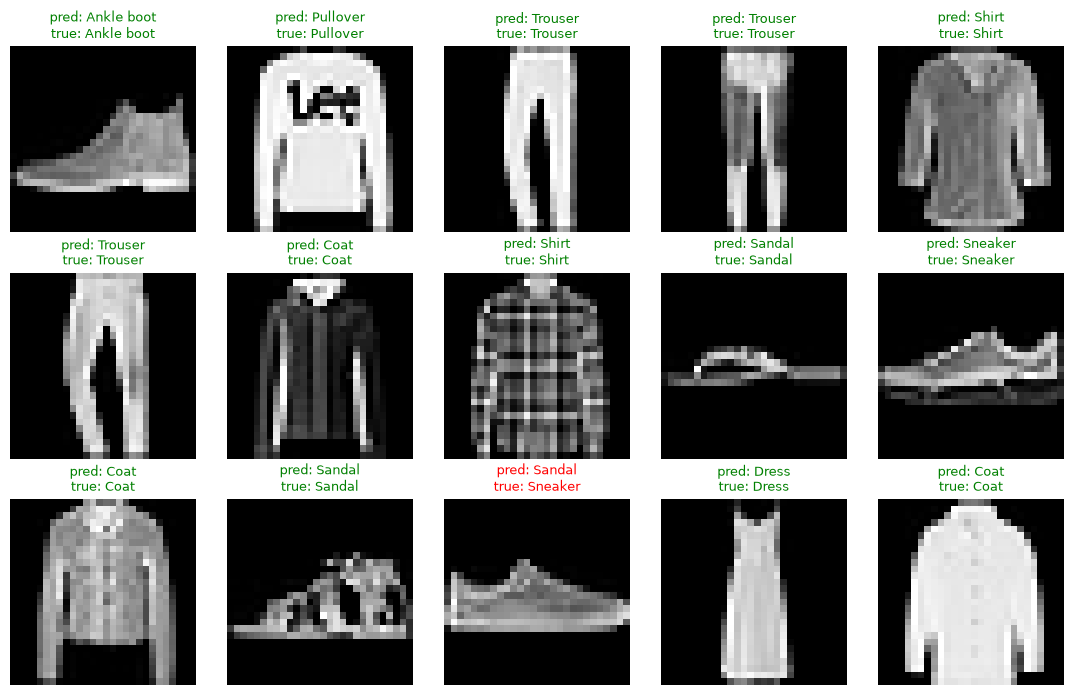

In [5]:
import matplotlib.pyplot as plt

# предсказания на первых 15 тестовых картинках
preds = model.predict(x_test[:15])
pred_labels = preds.argmax(axis=1)

fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i].squeeze(), cmap="gray")
    correct = pred_labels[i] == y_test[i]
    ax.set_title(
        f"pred: {class_names[pred_labels[i]]}\ntrue: {class_names[y_test[i]]}",
        color="green" if correct else "red",
        fontsize=9,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 239us/step


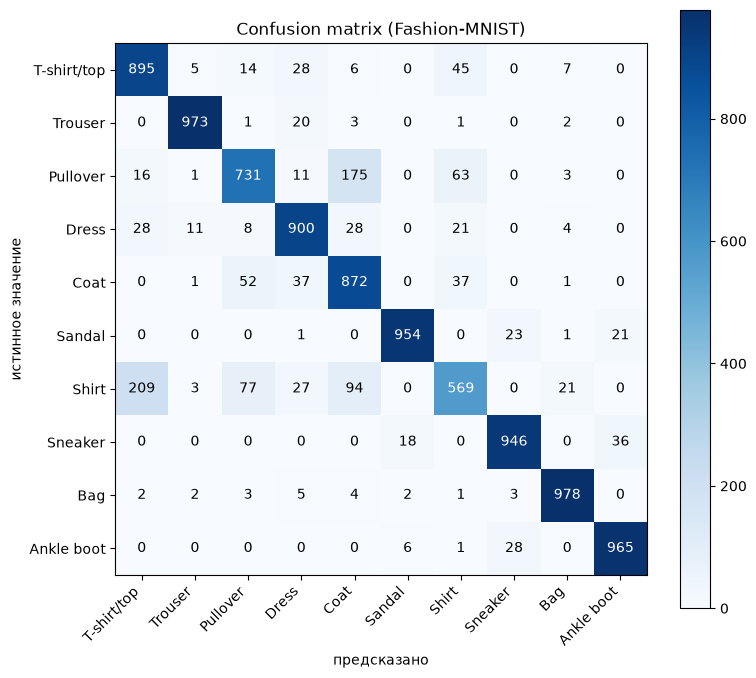

In [6]:
# confusion matrix: какие классы одежды модель чаще всего путает
all_preds = model.predict(x_test).argmax(axis=1)

confusion = np.zeros((10, 10), dtype=int)
for true, pred in zip(y_test, all_preds):
    confusion[true, pred] += 1

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)
ax.set_xlabel("предсказано")
ax.set_ylabel("истинное значение")
ax.set_title("Confusion matrix (Fashion-MNIST)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, confusion[i, j], ha="center", va="center",
                 color="white" if confusion[i, j] > confusion.max() / 2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.show()